# Principal Component Analysis (PCA)

PCA is a feature extraction technique. It takes many columns and turns them into fewer new columns, while keeping as much of the information as possible.

Some datasets have hundreds of columns. Many of them are related to each other, and a lot of them add noise. This makes models slow, hard to visualize, and more likely to overfit. This problem is often called the curse of dimensionality.

PCA fixes this by creating new columns called **principal components**. Each one is a mix of the old columns, and they are ordered by how much variation in the data they capture. We keep the first few and drop the rest.

PCA uses ideas we already built in the statistics notebooks: variance, covariance, and standardization.

In [45]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [8]:
df = sns.load_dataset("iris")
df.head(3)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa


In [9]:
X = df.drop(columns=['species']).values
X[:4,]

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2]])

In [29]:
# The iris dataset has four features, ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
# So it can't be visualised in 4D, we have to bring it into 2D while keeping the max variance.

# Before applying PCA the Standadization step is a good practice

ss = StandardScaler()
zx = ss.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(zx)

print("Transformed shape:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)

new_df = pd.DataFrame(X_pca, columns=['PCA1', 'PCA2'])
new_df['species'] = df['species']
new_df.head()

Transformed shape: (150, 2)
Explained variance ratio: [0.72962445 0.22850762]


,PCA1,PCA2,species
0,-2.264703,0.480027,setosa
1,-2.080961,-0.674134,setosa
2,-2.364229,-0.341908,setosa
3,-2.299384,-0.597395,setosa
4,-2.389842,0.646835,setosa


The explained variance means how much variance does each principle component explaines, here the PCA1 explains 72% while PCA2 explains 22% of the total variance 

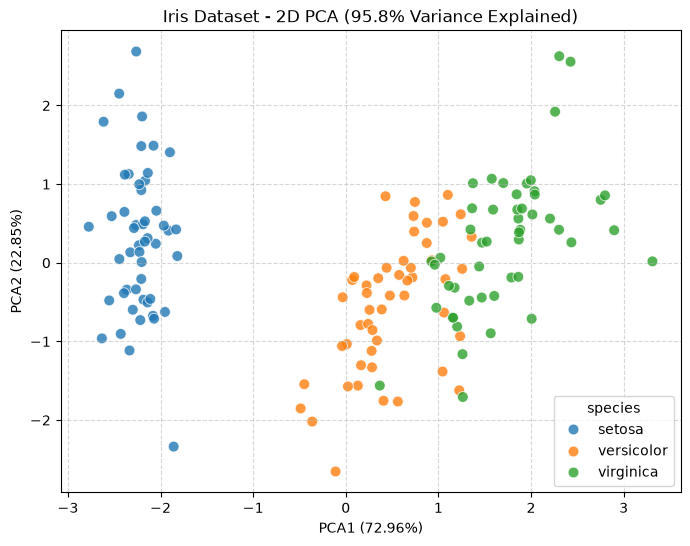

In [37]:
# now we can visualize it easily

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=new_df, 
    x='PCA1', 
    y='PCA2', 
    hue='species', 

    s=60, 
    alpha=0.8
)

plt.title('Iris Dataset - 2D PCA (95.8% Variance Explained)')
plt.xlabel('PCA1 (72.96%)')
plt.ylabel('PCA2 (22.85%)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# if we want to get 98 % variance we will set the n_component value to 0.98, the component will jump to 3 from 2

pca = PCA(n_components=.98)
X_pca = pca.fit_transform(zx)



print("Transformed shape:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)

df_3D = pd.DataFrame(X_pca, columns=['PCA1', 'PCA2', 'PCA3'])
df_3D['species'] = df['species']
df_3D.head()

Transformed shape: (150, 3)
Explained variance ratio: [0.72962445 0.22850762 0.03668922]


,PCA1,PCA2,PCA3,species
0,-2.264703,0.480027,0.127706,setosa
1,-2.080961,-0.674134,0.234609,setosa
2,-2.364229,-0.341908,-0.044201,setosa
3,-2.299384,-0.597395,-0.091290,setosa
4,-2.389842,0.646835,-0.015738,setosa


In [ ]:
import plotly.express as px

var_ratio = pca.explained_variance_ratio_ * 100
total_var = var_ratio.sum()

fig = px.scatter_3d(
    df_3D,
    x='PCA1',
    y='PCA2',
    z='PCA3',
    color='species',
    title=f'Iris Dataset - 3D PCA ({total_var:.2f}% Variance Explained)',
    labels={
        'PCA1': f'PCA1 ({var_ratio[0]:.2f}%)',
        'PCA2': f'PCA2 ({var_ratio[1]:.2f}%)',
        'PCA3': f'PCA3 ({var_ratio[2]:.2f}%)'
    },
    opacity=0.85
)

fig.update_traces(marker=dict(size=5, line=dict(width=0.5, color='DarkSlateGrey')))
fig.update_layout(margin=dict(l=0, r=0, b=0, t=40))
fig.show()


### Manual work

In PCA, we find unit vectors (directions) onto which projecting the data maximizes variance.
A unit vector is a vector with a magnitude (length) of 1: ||u|| = 1.

Standard variance formula:
Var(X) = (1/n) * ∑ᵢ₌₁ⁿ (xᵢ - x̄)²

Projected variance along a unit vector u:
Var(uᵀX) = (1/n) * ∑ᵢ₌₁ⁿ (uᵀxᵢ - uᵀx̄)²

Goal: Find the unit vector u that maximizes this projected variance.
Mathematically, the direction of maximum variance is given by the eigenvectors of the
covariance matrix (Σ), and the amount of variance along each direction equals its
corresponding eigenvalue (λ).

Eigenvector: A non-zero vector that does not change direction during a linear
transformation, it only gets scaled (stretched or shrunk) by a scalar factor λ:
Σv = λv  (or generally, Ax = λx)

The eigenvectors and eigenvalues are computed directly from the data's covariance matrix.


In [84]:
df = sns.load_dataset("iris")
X = df.drop(columns=['species']).values

Z = (X - X.mean(axis=0)) / X.std(axis=0)

cov_mat = np.cov(Z, rowvar=False)
cov_mat

array([[ 1.00671141, -0.11835884,  0.87760447,  0.82343066],
       [-0.11835884,  1.00671141, -0.43131554, -0.36858315],
       [ 0.87760447, -0.43131554,  1.00671141,  0.96932762],
       [ 0.82343066, -0.36858315,  0.96932762,  1.00671141]])

In [85]:
eigvals, eigvecs = np.linalg.eigh(cov_mat)

# sort largest first (eigenvalues AND eigenvectors together)
order = np.argsort(eigvals)[::-1]
eigvals = eigvals[order]
eigvecs = eigvecs[:, order]

ratio = eigvals / eigvals.sum()
for i, r in enumerate(ratio):
    print(f"PC{i+1}: {r*100:.2f}%   cumulative: {ratio[:i+1].sum()*100:.2f}%")

PC1: 72.96%   cumulative: 72.96%
PC2: 22.85%   cumulative: 95.81%
PC3: 3.67%   cumulative: 99.48%
PC4: 0.52%   cumulative: 100.00%


In [58]:
eigvecs

array([[-0.52106591,  0.37741762,  0.71956635,  0.26128628],
       [ 0.26934744,  0.92329566, -0.24438178, -0.12350962],
       [-0.5804131 ,  0.02449161, -0.14212637, -0.80144925],
       [-0.56485654,  0.06694199, -0.63427274,  0.52359713]])

In [86]:
# take the first two eigenvectors (columns) as the each column is a vector
U_reduce = eigvecs[:, :2]            # shape (4, 2)
U_reduce

array([[-0.52106591,  0.37741762],
       [ 0.26934744,  0.92329566],
       [-0.5804131 ,  0.02449161],
       [-0.56485654,  0.06694199]])

In [87]:
print("Z shape:", Z.shape)
print("U_reduce shape:", U_reduce.shape)

Z shape: (150, 4)
U_reduce shape: (4, 2)


In [88]:
# project every point
Z_pca = Z @ U_reduce                 # shape (150, 2)

# project every point
Z_pca = Z @ U_reduce           # As we know Var(U_reduceᵀX) here the U_reduce is already transformed  Z: (150, 4)  U_reduce: (4, 2)    it will gives (150, 2) matrix

print("Z_pca shape   :", Z_pca.shape)
print("First 5 projected points:\n", np.round(Z_pca[:5], 3))

Z_pca shape   : (150, 2)
First 5 projected points:
 [[ 2.265  0.48 ]
 [ 2.081 -0.674]
 [ 2.364 -0.342]
 [ 2.299 -0.597]
 [ 2.39   0.647]]


<Axes: xlabel='PCA1', ylabel='PCA2'>

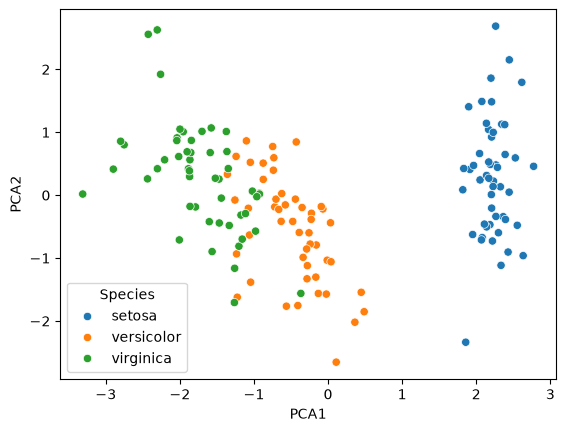

In [90]:
pca_df = pd.DataFrame(Z_pca, columns=['PCA1', 'PCA2'])
pca_df['Species'] = df['species']
pca_df

sns.scatterplot(data=pca_df, x='PCA1', y='PCA2', hue='Species')